# Fig. 10 / Fig. 11 — Listening budget, protection, and service cost

这是与 `Nulling_CDF_SectorDrop.ipynb` 平行的独立入口，对应论文说明文档第 9 节。

- **Fig. 10(a)**：活动覆盖失败概率（廉价 Monte Carlo、Wilson 区间、理论上界）。
- **Fig. 10(b)**：固定受保护用户集合上的最终 INR 超限率。
- **Fig. 11(a)**：每条 TN 服务链路的平均有效频谱效率，附两种 MRT 参考。
- **Fig. 11(b)**：实际数据传输期间的 INR 超限时间占比。

信道、活动试验、后处理分别存档。RT 只在所需信道缓存不存在时运行；改变 $p,L_{\rm s},\lambda$ 不重做 RT；改变时间参数、INR 阈值和置信区间设置只需后处理。

选择 **sionna20** kernel，重启内核后从上往下执行；当前默认是 **pilot**，直接复用已经生成的 3 个 RT 场景。正式起步网格使用 **paper**，扩展场景时须选择相应的新缓存或 `native` 生成入口。完整统计尚需实际运行，pilot 不作为论文性能结论。

[功能与输出说明](listening_experiments/README.md) · [论文实验设计第 9 节](overleaf_ntn_paper/SECTION_IV_D_MEETING_NOTES_C_EXPLAINED_zh.md#9-fig-1011-的具体实验与出图方案)

## 1. 导入与运行模式
`MODE="replot"` 时直接读取已完成试验，跳过 RT 和检测。所有新增 Python 函数位于 `listening_experiments/`。

In [8]:
from pathlib import Path
from dataclasses import asdict, replace
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "Nulling_CDF_SectorDrop.ipynb").is_file()), None)
if ROOT is None:
    raise RuntimeError("请从项目根目录或其子目录启动 notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from listening_experiments import (
    RTConfig, ExperimentConfig, MusicConfig, TimingConfig,
    prepare_channels, load_legacy_channels, load_cached_channels, run_experiment, analyze_run, plot_figures,
)

MODE = "run"                         # "run" 或 "replot"
PROFILE = "pilot"                    # "pilot" 或 "paper"
RUN_TO_REPLOT = None                  # replot 时填完整的 runs/<run_id> 路径
OUTPUT_ROOT = ROOT / "result" / "fig10_fig11"
print("Project:", ROOT)

Project: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction


## 2. 配置
固定每窗 $n_{\rm s}=128$，因此 $T=128L_{\rm s}$ 随监听预算增加。各 $p$ 共用均匀活动随机数，各 $L_{\rm s}$ 共用窗口前缀。各基站共享每个用户的活动与波形，噪声独立；所有静默窗口也保留噪声。

`pilot`：3 个场景 × 5 次重复，4 个窗口预算，2° MUSIC 搜索。`paper`：20 × 20，10 个预算，0.5° 搜索。后者只是正式统计的起步规模，仍需检查区间精度。

源数估计支持 `rank` 和 `mdl`，当前选择 `rank`；修改下方 `MUSIC.source_estimation` 对应的构造参数即可切换。当前使用纯噪声快拍标定的 rank 设置：相对阈值 `1e-5`，参考噪声裕量 `0.45`，参考快拍数 `128`；实际裕量为 `0.45 * sqrt(128/T)`。两种方法均使用有限快拍样本协方差，不生成 analytic 信号协方差。该规则适用于当前 8×8 阵列、6×6 前后向平滑和 T≥128；更改阵列、平滑、噪声模型或使用更短记录后需重新标定。

UL 活动功率显式采用 23 dBm。观测归一化为 $Y/\sqrt{P_{\rm UL}}$，噪声为 $N_{\rm BS}/P_{\rm UL}$，功率拟合保持信道增益单位。旧 CDF 的 analytic/rank 结果不能直接作为此处有限快拍基准。

In [9]:
if PROFILE not in {"pilot", "paper"} or MODE not in {"run", "replot"}:
    raise ValueError("Unknown PROFILE or MODE")
NUM_MACROS = 3 if PROFILE == "pilot" else 20
EXPERIMENT = ExperimentConfig(
    p_values=(0.1, 0.3, 1.0),
    listening_windows=(1, 4, 16, 64) if PROFILE == "pilot" else (1, 2, 4, 8, 16, 24, 32, 48, 57, 64),
    snapshots_per_window=128,
    episodes_per_scene=5 if PROFILE == "pilot" else 20,
    lambda_weight=1e11,
    ul_power_dbm=23.0, bs_power_dbm=35.0,
    bandwidth_ul=200e6, bandwidth_dl=200e6,
    bs_noise_figure_db=2.0, tn_noise_figure_db=7.0, ntn_noise_figure_db=3.0,
    inr_threshold_db=-3.0,
    ul_dl_power_correction=True,
    seed=20261013,
)
RT = RTConfig(
    scene_path="Denver_scene/10kmwithfigure/10km.xml",
    ntn_users=20, tx_rows=8, tx_cols=8,
    f_dl=7e9, f_ul=6.3e9, max_depth=3, ntn_los_mode="natural",
    bs_power_dbm=EXPERIMENT.bs_power_dbm,
    bandwidth=EXPERIMENT.bandwidth_dl,
    bs_noise_figure_db=EXPERIMENT.bs_noise_figure_db,
)
MUSIC = MusicConfig(
    source_estimation="rank",       # "rank" 或 "mdl"，当前使用 rank
    rank_relative_threshold=1e-5, rank_noise_margin=0.45,
    rank_noise_reference_snapshots=128,  # 实际裕量 = 0.45 * sqrt(128 / T)，T >= 128
    spatial_smoothing=True, subarray_rows=6, subarray_cols=6, forward_backward=True,
    grid_step_deg=2.0 if PROFILE == "pilot" else 0.5,
    peak_refine=True, max_noise_projection=0.2,
)
# 全部时间以一个监听窗口 tau_0 为单位。switch 已包含每窗两次切频的总时间。
TIMING = TimingConfig(horizon=256, listen=1, switch=0.1, gap=1, processing=1)
# replot 模式下实验网格/物理功率从归档读取；这里的 EXPERIMENT/RT/MUSIC 不替换旧记录。
ANALYSIS_THRESHOLD_DB = -3.0          # None 表示使用归档阈值
BOOTSTRAP_DRAWS = 2000
COVERAGE_SAMPLES = 100_000
COVERAGE_EPSILON = 0.05

for config in (RT, EXPERIMENT, MUSIC):
    config.validate()
if MODE == "run":
    for L in EXPERIMENT.listening_windows:
        d = TIMING.durations(L)        # 在耗时 RT 前检查是否 t_ready < H
        print(f"L={L:2d}, T={L * EXPERIMENT.snapshots_per_window:4d}, "
              f"C_RF/H={d['rf']/d['horizon']:.3f}, t_ready/H={d['ready']/d['horizon']:.3f}")
    if MUSIC.source_estimation == "rank":
        print("Rank noise margins:", {L: MUSIC.rank_margin_for_snapshots(L * EXPERIMENT.snapshots_per_window) for L in EXPERIMENT.listening_windows})

L= 1, T= 128, C_RF/H=0.004, t_ready/H=0.008
L= 4, T= 512, C_RF/H=0.017, t_ready/H=0.033
L=16, T=2048, C_RF/H=0.069, t_ready/H=0.131
L=64, T=8192, C_RF/H=0.275, t_ready/H=0.525
Rank noise margins: {1: 0.45, 4: 0.225, 16: 0.1125, 64: 0.05625}


## 3. RT 信道来源与持久缓存

- `cached`：当前默认，读取明确指定的旧信道目录，核对 RT 物理参数、文件身份和原始版本记录；更新 MUSIC 代码也不会重新追踪。扩展到超过缓存现有场景数时会报错。
- `native + auto`：生成新信道时使用；按场景资产、RT 参数和相关代码的指纹找缓存，只追踪缺失场景。增加场景数可复用已有前缀。
- `native + reuse_only`：要求信道已齐全，缺失即报错，绝不触发 RT。
- `legacy`：读取已有 SectorDrop `channels/` 下的 DL 与指定 `ul_XXX/` 目录。必须显式选择频段，程序会核对实际频率与阵列尺寸；不会改写原缓存。

`legacy` 的实际部署参数以原运行配置为准，当前 `RT` 中除频率外的生成参数不改变旧信道。缓存保留各用户、各基站、各阵元的复信道；多径已按原流程相干求和，适用于本组静态窄带实验。

In [10]:
CHANNEL_SOURCE = "cached"            # "cached" / "native" / "legacy"
CACHED_CHANNELS = ROOT / "result/fig10_fig11/channel_cache/324aed40805adac11ba8"
CACHE_POLICY = "auto"                # "auto" 或 "reuse_only"
CHANNEL_CACHE = OUTPUT_ROOT / "channel_cache"
LEGACY_CHANNELS = None                # 例如 ROOT / "result/<已有运行>/channels"
LEGACY_UL_SUBDIR = "ul_001"          # 必须确认其频率为 RT.f_ul；不自动猜选

channels = None
if MODE == "run":
    if CHANNEL_SOURCE == "cached":
        channels = load_cached_channels(CACHED_CHANNELS, num_macros=NUM_MACROS, expected_config=RT)
    elif CHANNEL_SOURCE == "native":
        channels = prepare_channels(RT, NUM_MACROS, CHANNEL_CACHE, policy=CACHE_POLICY, project_root=ROOT)
    elif CHANNEL_SOURCE == "legacy":
        if LEGACY_CHANNELS is None:
            raise ValueError("请填写 LEGACY_CHANNELS，或使用 CHANNEL_SOURCE='native'。")
        channels = load_legacy_channels(
            LEGACY_CHANNELS, ul_subdir=LEGACY_UL_SUBDIR,
            num_macros=NUM_MACROS, f_dl=RT.f_dl, f_ul=RT.f_ul,
        )
    else:
        raise ValueError("Unknown CHANNEL_SOURCE")
    print("Loaded macros:", len(channels), "NTN shape:", channels[0].h_ntn_dl.shape)
else:
    print("replot: 跳过全部信道生成和读取")

Reusing 3 frozen RT macros from /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/channel_cache/324aed40805adac11ba8; no ray tracing
Loaded macros: 3 NTN shape: (20, 1, 12, 64)


## 4. 活动试验与 MUSIC（rank / MDL 可选）
每个场景固定一轮 TN 配对和所有 DL 耦合的受保护 NTN 用户，包含从未发射和未检测到的用户。检测器仅接收累计样本协方差，不使用真实源数或方向。

每完成一个 `(macro, episode)` 保存一个 checkpoint；中断后用相同配置重跑会跳过完成的试验。当前未完成的 episode 会从其确定性随机种子重算。改变活动/检测配置会新建运行目录，继续使用相同 RT 缓存。

In [11]:
if MODE == "run":
    run_dir = run_experiment(channels, EXPERIMENT, MUSIC, OUTPUT_ROOT / "runs")
else:
    if RUN_TO_REPLOT is None:
        raise ValueError("MODE='replot' 时请填写 RUN_TO_REPLOT。")
    run_dir = Path(RUN_TO_REPLOT).expanduser().resolve()
print("Saved run (下次 replot 使用此路径):", run_dir.resolve())

Run outputs: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/runs/024a46c618b9d78e3fe1
[1/15] macro=0 episode=0: checkpoint hit
[2/15] macro=0 episode=1: checkpoint hit
[3/15] macro=0 episode=2: checkpoint hit
[4/15] macro=0 episode=3: checkpoint hit
[5/15] macro=0 episode=4: checkpoint hit
[6/15] macro=1 episode=0: checkpoint hit
[7/15] macro=1 episode=1: checkpoint hit
[8/15] macro=1 episode=2: checkpoint hit
[9/15] macro=1 episode=3: checkpoint hit
[10/15] macro=1 episode=4: checkpoint hit
[11/15] macro=2 episode=0: checkpoint hit
[12/15] macro=2 episode=1: checkpoint hit
[13/15] macro=2 episode=2: checkpoint hit
[14/15] macro=2 episode=3: checkpoint hit
[15/15] macro=2 episode=4: checkpoint hit
Saved run (下次 replot 使用此路径): /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/runs/024a46c618b9d78e3fe1


## 5. 共用统计与时间核算
独立场景等权，场景内活动重复等权，试验内用户或服务链路等权。对整个场景做配对 bootstrap，保持跨 $p,L_{\rm s}$ 的对应关系。

Fig. 10(a) 另用廉价活动抽样核对覆盖模型；使用实际受保护人数 $N_m$。其区间是活动模型的抽样区间，其他三个面板使用场景聚类区间。

Fig. 11 使用同一批线性 INR/SINR；监听和切频不传数据，间隔和非阻塞处理用 MRT，最终波束完成后用 nulling。$R_{\rm eff}$ 按整个 $H$ 归一化，$q_{\rm data}$ 按 $H-C_{\rm RF}$ 归一化。只修改本节参数并重跑后续单元即可重新核算，**无需重跑 RT 或 MUSIC**。

In [12]:
analysis = analyze_run(
    run_dir, TIMING, threshold_db=ANALYSIS_THRESHOLD_DB,
    bootstrap_draws=BOOTSTRAP_DRAWS, coverage_samples=COVERAGE_SAMPLES,
    coverage_epsilon=COVERAGE_EPSILON, seed=20261014,
)
print("Independent scenes:", analysis["independent_scenes"])
print("Protected users per scene:", analysis["protected_counts"])

Analysis outputs: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/runs/024a46c618b9d78e3fe1/analysis/1fdee43febe48c81
Independent scenes: 3
Protected users per scene: [18, 17, 19]


## 6. Fig. 10、11：带点与 95% 区间的折线图
自动导出 PDF 和 PNG。只有一个场景时不绘制虚假的场景置信区间；零观测超限不等于真实风险为零。

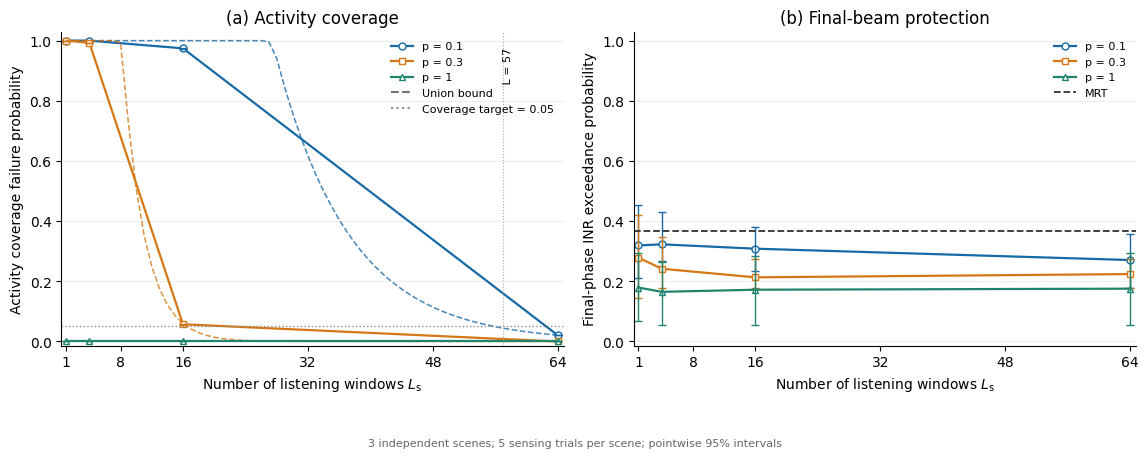

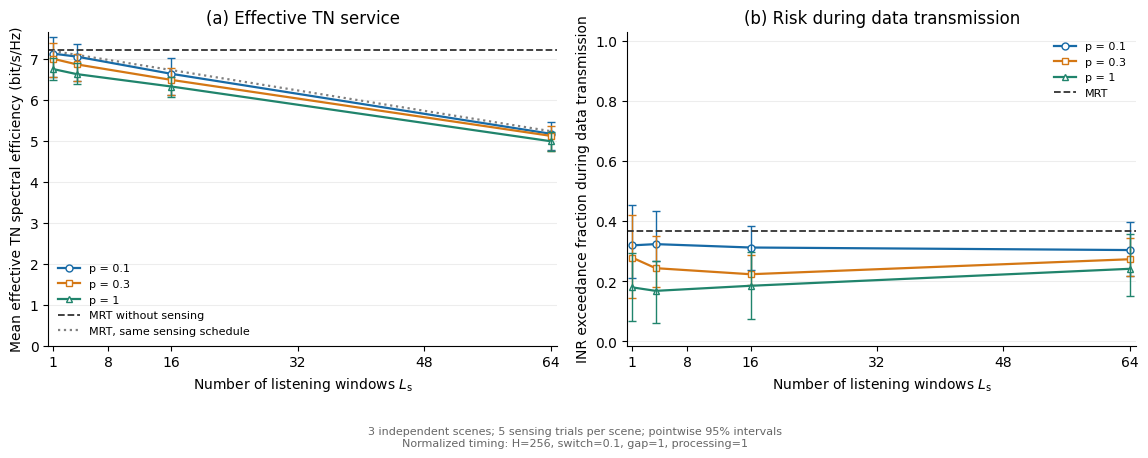

Figures and CSV: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/runs/024a46c618b9d78e3fe1/analysis/1fdee43febe48c81


In [13]:
fig10, fig11 = plot_figures(analysis)
display(fig10)
display(fig11)
plt.close(fig10)
plt.close(fig11)
print("Figures and CSV:", analysis["directory"])

## 7. 工作点数值与归档
下面显示当前网格的结果；CSV 同时保存逐点置信区间、诊断指标和时间占比。

In [14]:
print(f"{'p':>5} {'L':>4} {'q_miss MC':>11} {'q_out':>9} {'R_eff':>10} {'q_data':>9} {'empty BS':>10}")
coverage = {(r["p"], r["L"]): r for r in analysis["coverage"]}
for r in analysis["summary"]:
    c = coverage[(r["p"], r["L"])]
    print(f"{r['p']:5.2f} {r['L']:4d} {c['q_miss_mc']:11.4f} {r['q_out']:9.4f} "
          f"{r['r_eff']:10.4f} {r['q_data']:9.4f} {r['empty_detection_fraction']:10.4f}")
print("Config:", run_dir / "ac_config.json")
print("Raw user/link records:", run_dir / "episodes")
print("Analysis:", Path(analysis["directory"]) / "analysis.json")

    p    L   q_miss MC     q_out      R_eff    q_data   empty BS
 0.10    1      1.0000    0.3193     7.1356    0.3195     0.9278
 0.10    4      1.0000    0.3229     7.0630    0.3236     0.8056
 0.10   16      0.9744    0.3085     6.6416    0.3124     0.6444
 0.10   64      0.0212    0.2707     5.1786    0.3039     0.5056
 0.30    1      1.0000    0.2787     7.0111    0.2790     0.7778
 0.30    4      0.9929    0.2417     6.8731    0.2437     0.5889
 0.30   16      0.0572    0.2132     6.4934    0.2236     0.4722
 0.30   64      0.0000    0.2241     5.1282    0.2734     0.3833
 1.00    1      0.0000    0.1793     6.7598    0.1800     0.4722
 1.00    4      0.0000    0.1651     6.6357    0.1683     0.4111
 1.00   16      0.0000    0.1721     6.3322    0.1852     0.3500
 1.00   64      0.0000    0.1756     4.9968    0.2416     0.2500
Config: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/fig10_fig11/runs/024a46c618b9d78e3fe1/ac_config.json
Raw user/link records: /home/sh

## 8. 重跑时怎么选择

| 要改什么 | 重跑哪些部分 | 是否需要 RT |
|---|---|---|
| $p,L_{\rm s},n_{\rm s},\lambda$、UL 功率、噪声、MUSIC 参数 | 配置、信道读取、活动试验、统计与画图 | `cached` 显式复用旧信道；或 `native` 命中同版本缓存 |
| $H$、切频/间隔/处理时间、INR 阈值、bootstrap 数量 | `MODE="replot"` + `RUN_TO_REPLOT`，或直接重跑第 5 节以后 | 否，也无需 MUSIC |
| 图形样式 | 修改 `listening_experiments/plotting.py` 后重载模块，执行第 6 节；也可 `plot_figures(".../analysis.json")` | 否 |
| 场景、阵列、UL/DL 频率或其他 RT 生成参数 | 生成新的信道缓存，再运行活动试验 | 是，仅生成缺失场景 |
| 仅增加独立场景数 | 同配置增加 `NUM_MACROS` | 仅新增场景需要 RT；新的整体运行会重算活动试验 |

本轮保留旧结果目录，并在 `result/fig10_fig11/notebook_history/` 备份修改前的已执行 notebook。当前源文件清除旧输出以免与新参数混淆。新参数运行会生成独立结果目录。

相同网格与重复数支持 episode 断点续跑；更改网格或重复数建立新的运行档案，不混合不同配置。`ac_config.json` 记录物理配置与代码指纹，时间参数独立记录在 `analysis/<analysis_id>/analysis.json`。

本程序不实现式 (40) 的数值验证，也不把固定 $n_{\rm s}$ 的预算扫描解释为固定总快拍数下“连续 vs 分开感知”的性能对比。分组累计与整体协方差的一致性由 `listening_experiments/tests/` 的检查覆盖。

命令行检查：`OPENBLAS_NUM_THREADS=1 MPLBACKEND=Agg python -m unittest discover -s listening_experiments/tests -v`。